# Chapter 3 — Dimensionality Reduction Techniques

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

Data di dunia nyata sering memiliki puluhan hingga ribuan fitur. Semakin banyak dimensi, semakin "kosong" ruang fiturnya (*curse of dimensionality*): jarak antar titik menjadi kurang bermakna, model lebih mudah *overfitting*, komputasi membengkak, dan data mustahil divisualisasikan secara langsung. **Reduksi dimensi** (*dimensionality reduction*) adalah sekumpulan teknik untuk memetakan data berdimensi tinggi $\mathbb{R}^p$ ke ruang berdimensi rendah $\mathbb{R}^k$ ($k \ll p$) sambil mempertahankan sebanyak mungkin informasi yang relevan — entah itu variansi (PCA), keterpisahan kelas (LDA), atau struktur ketetanggaan lokal (t-SNE).

Chapter ini membahas tiga teknik utama yang tersedia di scikit-learn, masing-masing mewakili paradigma berbeda:

| Teknik | Jenis | Linear? | Tujuan yang dioptimalkan |
|---|---|---|---|
| PCA | *Unsupervised* | Ya | Memaksimalkan variansi hasil proyeksi |
| LDA | *Supervised* | Ya | Memaksimalkan rasio sebaran antar-kelas / dalam-kelas |
| t-SNE | *Unsupervised* | Tidak (*manifold learning*) | Mempertahankan kemiripan lokal (minimisasi KL divergence) |

### Daftar Isi
- **Import Library**
- **3.1 Principal Component Analysis (PCA)** — dataset Wine, proyeksi 2D, *explained variance*, PCA sebagai rotasi sumbu, verifikasi lewat eigendekomposisi/SVD
- **3.2 Linear Discriminant Analysis (LDA)** — proyeksi supervised, perbandingan PCA vs LDA
- **3.3 t-SNE untuk Visualisasi Data** — dataset Digits (8×8 *handwritten digits*)
- **3.4 Latihan** — (1) PCA + Logistic Regression, (2) t-SNE untuk visualisasi hasil *clustering* K-Means
- **Ringkasan Chapter 3**

> **Catatan:** Notebook ini mereproduksi kode dari Chapter 3 buku (berdasarkan notebook resmi penerbit, dengan sedikit penyesuaian agar kompatibel dengan scikit-learn 1.9 dan lebih jelas), lalu menjelaskan teori di balik setiap teknik beserta interpretasi output-nya. Semua penjelasan ditulis ulang dalam Bahasa Indonesia.

## Import Library

Seluruh library utama di-*import* di sini. Library tambahan (misalnya kelas model tertentu) juga di-*import* ulang di resep masing-masing agar setiap resep tetap mudah dibaca secara mandiri, mengikuti gaya buku.

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_wine, load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE

# Seed global untuk reprodusibilitas & sembunyikan FutureWarning
np.random.seed(2024)
warnings.simplefilter(action='ignore', category=FutureWarning)

# Ukuran figure moderat agar file notebook tidak terlalu besar
plt.rcParams['figure.dpi'] = 80

print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.9.1


## 3.1 Principal Component Analysis (PCA)

**Teori:**

PCA adalah teknik reduksi dimensi **linear** dan **unsupervised** (tidak memakai label). Idenya: cari sistem koordinat baru yang sumbu-sumbunya (*principal components*, PC) diurutkan berdasarkan seberapa besar variansi data yang ditangkapnya. PC pertama adalah arah dengan variansi terbesar, PC kedua adalah arah dengan variansi terbesar berikutnya **dengan syarat ortogonal** terhadap PC pertama, dan seterusnya.

**1. Formulasi sebagai masalah optimasi.** Misalkan $X \in \mathbb{R}^{n\times p}$ adalah matriks data yang sudah **di-*center*** (rata-rata tiap kolom = 0). Proyeksi data ke sebuah vektor satuan $\mathbf{w}$ adalah $X\mathbf{w}$, dengan variansi

$$
\operatorname{Var}(X\mathbf{w}) = \frac{1}{n-1}\,\mathbf{w}^\top X^\top X\,\mathbf{w} = \mathbf{w}^\top \Sigma\,\mathbf{w},
\qquad \Sigma = \frac{1}{n-1}X^\top X .
$$

PC pertama adalah solusi dari

$$
\mathbf{w}_1 = \arg\max_{\|\mathbf{w}\|=1} \mathbf{w}^\top \Sigma \mathbf{w}.
$$

Dengan pengali Lagrange $\mathcal{L} = \mathbf{w}^\top\Sigma\mathbf{w} - \lambda(\mathbf{w}^\top\mathbf{w}-1)$ dan $\partial\mathcal{L}/\partial\mathbf{w}=0$ diperoleh

$$
\Sigma\mathbf{w} = \lambda\mathbf{w},
$$

yaitu **persamaan eigen**. Variansi hasil proyeksi sama dengan $\mathbf{w}^\top\Sigma\mathbf{w} = \lambda$, sehingga PC pertama adalah *eigenvector* dengan *eigenvalue* terbesar. Secara umum, $k$ PC pertama adalah $k$ *eigenvector* teratas dari matriks kovarians:

$$
\Sigma = W \Lambda W^\top,\quad \Lambda = \operatorname{diag}(\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_p \ge 0),\quad W^\top W = I .
$$

Karena $\Sigma$ simetris dan semi-definit positif, semua eigenvalue real dan non-negatif, dan eigenvector-nya saling ortogonal — inilah alasan PC-PC saling tegak lurus.

**2. Hubungan dengan SVD.** Dalam praktik (termasuk di scikit-learn) PCA dihitung lewat *Singular Value Decomposition* dari data ter-*center*:

$$
X = U S V^\top \;\Rightarrow\; \Sigma = \frac{1}{n-1} V S^2 V^\top .
$$

Jadi kolom $V$ (baris dari `pca.components_`) adalah arah PC, dan $\lambda_j = s_j^2/(n-1)$ (atribut `explained_variance_`). Data hasil transformasi (*scores*) adalah $Z = XV_k = U_kS_k$. SVD lebih stabil secara numerik daripada membentuk $X^\top X$ secara eksplisit.

**3. Explained variance ratio.** Proporsi variansi total yang dijelaskan PC ke-$j$:

$$
\text{EVR}_j = \frac{\lambda_j}{\sum_{i=1}^{p}\lambda_i},
\qquad
\text{Kumulatif}(k) = \frac{\sum_{j=1}^{k}\lambda_j}{\sum_{i=1}^{p}\lambda_i}.
$$

Jumlah komponen $k$ biasanya dipilih agar variansi kumulatif mencapai ambang tertentu (mis. 90–95%), atau dengan melihat "siku" pada *scree plot*.

**4. Sudut pandang rekonstruksi.** PCA juga merupakan proyeksi linear ke subruang berdimensi $k$ yang **meminimalkan galat rekonstruksi kuadrat**:

$$
\min_{W_k^\top W_k = I}\; \| X - X W_k W_k^\top \|_F^2 = (n-1)\sum_{j=k+1}^{p}\lambda_j .
$$

Memaksimalkan variansi yang dipertahankan ekuivalen dengan meminimalkan variansi yang dibuang.

**5. Mengapa harus di-*scale*?** PCA mengejar variansi, sehingga fitur dengan satuan besar (mis. `proline` pada dataset Wine, nilainya ratusan–ribuan) akan mendominasi PC pertama hanya karena skalanya. Dengan `StandardScaler` setiap fitur menjadi $z = (x-\mu)/\sigma$, sehingga PCA bekerja pada **matriks korelasi**, bukan kovarians mentah.

**Getting ready.** Kita memakai dataset **Wine** bawaan scikit-learn: 178 sampel anggur dari 3 kultivar (kelas), dengan 13 fitur hasil analisis kimia (alkohol, asam malat, flavanoid, prolin, dsb.).

In [2]:
# Load dataset Wine
wine = load_wine()
df_wine = pd.DataFrame(data=wine.data, columns=wine.feature_names)
target_wine = wine.target

print('Shape data :', df_wine.shape)
print('Kelas      :', list(wine.target_names), '-> jumlah per kelas:', np.bincount(target_wine))
display(df_wine.head(10))

Shape data : (178, 13)
Kelas      : [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')] -> jumlah per kelas: [59 71 48]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0


**Interpretasi:** Dataset Wine berisi 178 baris × 13 fitur numerik dengan tiga kelas yang cukup seimbang (59, 71, 48 sampel). Perhatikan perbedaan skala antarfitur: `proline` bernilai ratusan hingga >1000, `magnesium` sekitar 100, sedangkan `hue` atau `nonflavanoid_phenols` di bawah 1. Perbedaan skala inilah yang membuat standardisasi wajib dilakukan sebelum PCA.

### 3.1.1 How to do it — PCA ke 2 dimensi dalam `Pipeline`

`Pipeline` merangkai *preprocessing* (`StandardScaler`) dan PCA menjadi satu estimator. Keuntungannya: parameter *scaling* (rata-rata & simpangan baku) dipelajari bersamaan saat `fit`, mencegah *data leakage* ketika nanti dipakai bersama *cross-validation*, dan kode menjadi ringkas. Setelah transformasi, kita plot data pada ruang PC1–PC2 dan menggambar vektor arah PC (diskalakan agar terlihat).

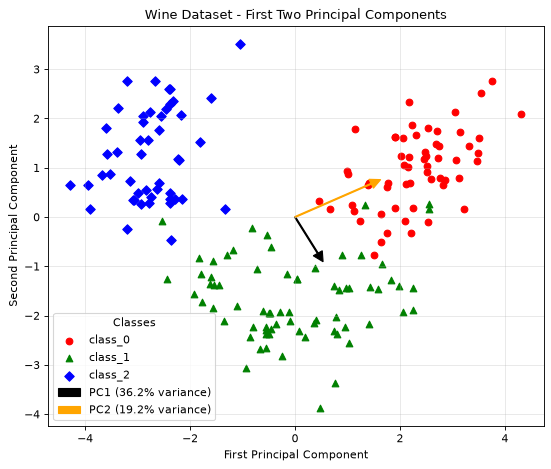

Shape setelah PCA: (178, 2)


In [3]:
# Pipeline: standardisasi -> PCA 2 komponen
pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),  # selalu scaling sebelum PCA
    ('pca', PCA(n_components=2))   # reduksi ke 2 dimensi
])

# Fit dan transform data
X_pca = pca_pipeline.fit_transform(df_wine)

# Visualisasi data hasil transformasi
plt.figure(figsize=(8, 6.5))
shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']

# Scatter per kelas
for i, (shape, color) in enumerate(zip(shapes, colors)):
    plt.scatter(X_pca[target_wine == i, 0], X_pca[target_wine == i, 1],
                c=color, marker=shape, label=wine.target_names[i])

# Ambil komponen PCA dan gambar sebagai vektor dari titik asal
pca = pca_pipeline.named_steps['pca']
origin = np.zeros(2)
arrow_colors = ['black', 'orange']

# Vektor diskalakan agar terlihat jelas pada plot
scaling = 3
for i, (component, ratio) in enumerate(zip(pca.components_, pca.explained_variance_ratio_)):
    plt.arrow(origin[0], origin[1],
              component[0] * scaling, component[1] * scaling,
              color=arrow_colors[i],
              width=0.02, head_width=0.2, head_length=0.2,
              label=f'PC{i+1} ({ratio:.1%} variance)')

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - First Two Principal Components')
plt.legend(title='Classes')
plt.grid(True, alpha=0.3)
plt.show()

print('Shape setelah PCA:', X_pca.shape)

**Interpretasi:** Data 13 dimensi berhasil diringkas menjadi 2 dimensi (`(178, 2)`), dan ketiga kultivar sudah membentuk tiga kelompok yang cukup jelas — padahal PCA **sama sekali tidak melihat label**. `class_0` (kanan) dan `class_2` (kiri) terpisah di sepanjang sumbu PC1, sedangkan `class_1` berada di tengah sumbu PC1 tetapi turun ke nilai PC2 negatif dan lebih menyebar, dengan beberapa titik bersinggungan dengan `class_0`. Ini menunjukkan bahwa arah variansi terbesar dalam data kimia anggur kebetulan juga sangat berkaitan dengan perbedaan kultivar.

Catatan teknis: vektor panah digambar dari `pca.components_` yang memiliki dimensi 13 (ruang fitur asli); di sini hanya dua elemen pertamanya yang dipakai sebagai koordinat, sehingga panah tersebut lebih bersifat ilustratif (mengikuti kode buku) daripada arah PC yang sesungguhnya — di ruang PC sendiri, PC1 dan PC2 tentu sejajar dengan sumbu-x dan sumbu-y.

### 3.1.2 How it works — Explained Variance Ratio

**Teori:** Setiap PC membawa sejumlah variansi $\lambda_j$. Atribut `explained_variance_ratio_` berisi $\lambda_j / \sum_i \lambda_i$ — proporsi informasi (dalam arti variansi) yang dipertahankan oleh komponen tersebut. Jumlah rasio dari komponen yang dipertahankan memberi tahu seberapa besar "harga" yang kita bayar saat membuang dimensi lain: jika dua PC menjelaskan 55% variansi, berarti 45% variansi dibuang (namun belum tentu itu informasi yang relevan untuk tugas tertentu).

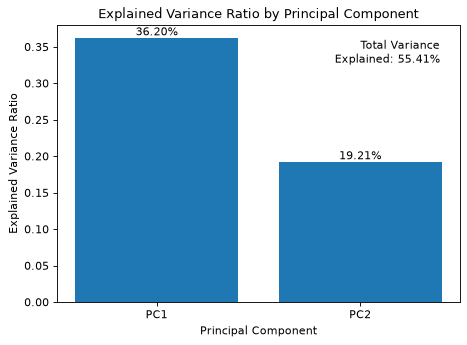

In [4]:
# Explained variance ratio dari 2 komponen
pca = pca_pipeline.named_steps['pca']
explained_variance_ratio = pca.explained_variance_ratio_

# Variansi kumulatif yang dijelaskan
cumulative_variance = np.sum(explained_variance_ratio)

# Bar chart
fig, ax = plt.subplots(figsize=(6.5, 4.5))

x = np.arange(1, len(explained_variance_ratio) + 1)
y = explained_variance_ratio
bars = ax.bar(x, y)

# Label persentase di atas tiap bar
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2., height,
            f'{height:.2%}', ha='center', va='bottom')

# Teks variansi kumulatif di pojok kanan atas
ax.text(0.95, 0.95, f'Total Variance\nExplained: {cumulative_variance:.2%}',
        transform=ax.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

ax.set_xticks(x)
ax.set_xticklabels(['PC1', 'PC2'])
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('Explained Variance Ratio by Principal Component')
plt.show()

**Interpretasi:** PC1 menjelaskan sekitar **36,2%** variansi dan PC2 sekitar **19,2%**, total ≈ **55,4%**. Artinya plot 2D sebelumnya hanya "melihat" sedikit lebih dari separuh variansi data terstandardisasi. Meski demikian, separuh variansi itu sudah cukup untuk memisahkan ketiga kelas secara visual — bukti bahwa informasi diskriminatif terkonsentrasi di beberapa arah utama. Untuk tugas prediktif, biasanya kita menyimpan lebih banyak komponen (lihat bagian verifikasi di bawah).

### 3.1.3 PCA sebagai rotasi sumbu (contoh 2 fitur)

**Teori:** Jika jumlah komponen sama dengan jumlah fitur ($k=p$), PCA **tidak membuang informasi apa pun** — ia hanya **merotasi** (dan mungkin mencerminkan) sistem koordinat sehingga sumbu baru sejajar dengan arah variansi terbesar dan data hasil transformasi menjadi **tidak berkorelasi** (matriks kovarians di ruang PC adalah diagonal $\Lambda$).

Untuk dua fitur terstandardisasi dengan korelasi $r$, matriks korelasinya

$$
R = \begin{pmatrix}1 & r\\ r & 1\end{pmatrix}
$$

memiliki eigenvalue $\lambda_{1,2} = 1 \pm |r|$ dengan eigenvector $\tfrac{1}{\sqrt2}(1,\,\pm1)^\top$ — selalu pada sudut 45°. Maka rasio variansi PC1 adalah $(1+|r|)/2$: semakin kuat korelasi kedua fitur, semakin besar variansi yang "dipadatkan" ke PC1. Jika $r\approx 0$, kedua PC membawa variansi hampir sama dan PCA hampir tidak berguna untuk reduksi.

Kode berikut membandingkan dua pasangan fitur: `alcohol` vs `malic_acid` (korelasi lemah) dan `flavanoids` vs `proanthocyanins` (korelasi kuat).

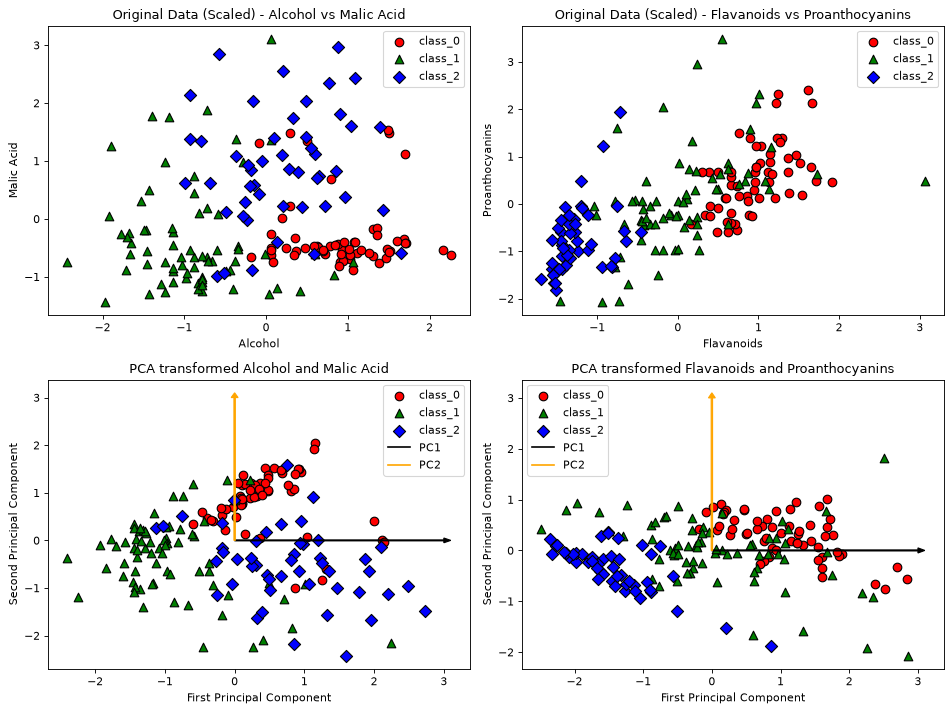

alcohol vs malic_acid            korelasi r = 0.094 | EVR = [0.547 0.453] | (1+|r|)/2 = 0.547
    components_ = [[0.707, 0.707], [0.707, -0.707]]
flavanoids vs proanthocyanins    korelasi r = 0.653 | EVR = [0.826 0.174] | (1+|r|)/2 = 0.826
    components_ = [[0.707, 0.707], [0.707, -0.707]]


In [5]:
# Pasangan fitur 1: 'alcohol' dan 'malic_acid'
features_1 = ['alcohol', 'malic_acid']
df_wine_subset_1 = pd.DataFrame(StandardScaler().fit_transform(df_wine[features_1]), columns=features_1)
pca_2d_1 = PCA(n_components=2)
X_pca_2d_1 = pca_2d_1.fit_transform(df_wine_subset_1)

# Pasangan fitur 2: 'flavanoids' dan 'proanthocyanins'
features_2 = ['flavanoids', 'proanthocyanins']
df_wine_subset_2 = pd.DataFrame(StandardScaler().fit_transform(df_wine[features_2]), columns=features_2)
pca_2d_2 = PCA(n_components=2)
X_pca_2d_2 = pca_2d_2.fit_transform(df_wine_subset_2)

# Grid 2x2: baris atas = data asli (scaled), baris bawah = hasil PCA
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

def scatter_kelas(ax, xs, ys):
    # Helper: scatter per kelas dengan marker & warna berbeda
    for i, (shape, color) in enumerate(zip(shapes, colors)):
        mask = target_wine == i
        ax.scatter(xs[mask], ys[mask], marker=shape, c=color, edgecolor='k', s=60,
                   label=wine.target_names[i])

# Kiri atas: data asli pasangan 1
scatter_kelas(axes[0, 0], df_wine_subset_1['alcohol'].values, df_wine_subset_1['malic_acid'].values)
axes[0, 0].set_xlabel('Alcohol'); axes[0, 0].set_ylabel('Malic Acid')
axes[0, 0].set_title('Original Data (Scaled) - Alcohol vs Malic Acid')
axes[0, 0].legend()

# Kanan atas: data asli pasangan 2
scatter_kelas(axes[0, 1], df_wine_subset_2['flavanoids'].values, df_wine_subset_2['proanthocyanins'].values)
axes[0, 1].set_xlabel('Flavanoids'); axes[0, 1].set_ylabel('Proanthocyanins')
axes[0, 1].set_title('Original Data (Scaled) - Flavanoids vs Proanthocyanins')
axes[0, 1].legend()

# Kiri bawah & kanan bawah: data hasil PCA + sumbu PC (di ruang PC, PC = sumbu standar)
arrow_colors_1 = ['black', 'orange']
scaling = 3
for ax, X_p, judul in [(axes[1, 0], X_pca_2d_1, 'PCA transformed Alcohol and Malic Acid'),
                       (axes[1, 1], X_pca_2d_2, 'PCA transformed Flavanoids and Proanthocyanins')]:
    scatter_kelas(ax, X_p[:, 0], X_p[:, 1])
    for i, component in enumerate(np.eye(2)):
        ax.arrow(0, 0, component[0] * scaling, component[1] * scaling,
                 color=arrow_colors_1[i], width=0.02, head_width=0.1, head_length=0.1)
        ax.plot([], [], color=arrow_colors_1[i], label=f'PC{i+1}')
    ax.set_xlabel('First Principal Component'); ax.set_ylabel('Second Principal Component')
    ax.set_title(judul)
    ax.legend()

plt.tight_layout()
plt.show()

# Ringkasan numerik
for nama, df_s, p in [('alcohol vs malic_acid', df_wine_subset_1, pca_2d_1),
                      ('flavanoids vs proanthocyanins', df_wine_subset_2, pca_2d_2)]:
    r = np.corrcoef(df_s.values.T)[0, 1]
    print(f'{nama:32s} korelasi r = {r:.3f} | EVR = {np.round(p.explained_variance_ratio_, 3)} '
          f'| (1+|r|)/2 = {(1 + abs(r)) / 2:.3f}')
    print('    components_ =', np.round(p.components_, 3).tolist())

**Interpretasi:**
- **Alcohol vs Malic Acid**: korelasinya sangat lemah ($r \approx 0{,}09$), sehingga PC1 hanya menjelaskan ≈ 54,7% dan PC2 ≈ 45,3%. Plot hasil PCA terlihat seperti versi terotasi 45° dari plot asli — tidak ada dimensi yang bisa dibuang tanpa kehilangan banyak informasi.
- **Flavanoids vs Proanthocyanins**: korelasinya kuat ($r \approx 0{,}65$), sehingga PC1 menjelaskan ≈ 82,6% variansi. Data hasil PCA memanjang di sepanjang PC1, dan PC1 sendiri sudah memisahkan `class_0` (kanan) dan `class_2` (kiri) dengan cukup baik; PC2 bisa dibuang dengan kehilangan informasi yang kecil.
- Nilai EVR tepat sama dengan rumus teoretis $(1+|r|)/2$, dan `components_` keduanya adalah $\pm\tfrac{1}{\sqrt2}(1,\pm1)$ ≈ `0.707`, mengonfirmasi analisis eigen di atas.

### 3.1.4 Tambahan: verifikasi PCA lewat eigendekomposisi & SVD, serta *scree plot*

**Teori:** Untuk memperkuat pemahaman, kita menghitung PCA secara manual dengan NumPy dan membandingkannya dengan hasil scikit-learn. Kita juga melihat variansi kumulatif seluruh 13 komponen untuk memutuskan berapa komponen yang layak dipertahankan. (Bagian ini merupakan tambahan dari kami, bukan bagian dari kode buku.)

Eigenvalue (eig) : [4.7324 2.5111 1.4542 0.9242 0.858 ]
s^2/(n-1) (SVD)  : [4.7324 2.5111 1.4542 0.9242 0.858 ]
explained_var_   : [4.7324 2.5111 1.4542 0.9242 0.858 ]
PC1 sama (abs)?  : True
Kovarians skor PC diagonal? True


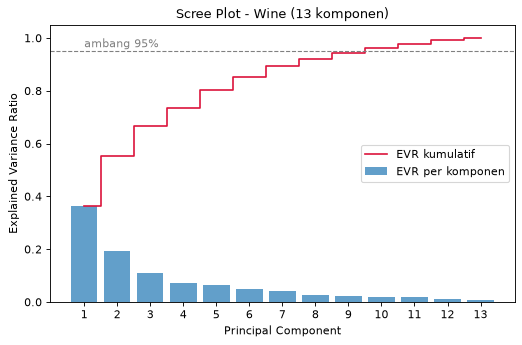

Komponen minimum untuk >=95% variansi: 10  (kumulatif = 0.962)

Loading PC1 (diurutkan):
nonflavanoid_phenols           -0.299
malic_acid                     -0.245
alcalinity_of_ash              -0.239
color_intensity                -0.089
ash                            -0.002
magnesium                       0.142
alcohol                         0.144
proline                         0.287
hue                             0.297
proanthocyanins                 0.313
od280/od315_of_diluted_wines    0.376
total_phenols                   0.395
flavanoids                      0.423


In [6]:
# Data terstandardisasi (mean 0, std 1)
X_std = StandardScaler().fit_transform(df_wine)
n = X_std.shape[0]

# (a) Eigendekomposisi matriks kovarians
cov = np.cov(X_std, rowvar=False)                  # 13 x 13
eigvals, eigvecs = np.linalg.eigh(cov)             # eigh: untuk matriks simetris
idx = np.argsort(eigvals)[::-1]                    # urutkan menurun
eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]

# (b) SVD dari data ter-center
U, S, Vt = np.linalg.svd(X_std, full_matrices=False)
var_svd = S**2 / (n - 1)

# (c) PCA scikit-learn dengan semua komponen
pca_full = PCA().fit(X_std)

print('Eigenvalue (eig) :', np.round(eigvals[:5], 4))
print('s^2/(n-1) (SVD)  :', np.round(var_svd[:5], 4))
print('explained_var_   :', np.round(pca_full.explained_variance_[:5], 4))
# Tanda eigenvector bisa terbalik (±), jadi bandingkan nilai mutlaknya
print('PC1 sama (abs)?  :', np.allclose(np.abs(eigvecs[:, 0]), np.abs(pca_full.components_[0])))
# Skor PCA tidak berkorelasi -> kovariansnya diagonal
Z = pca_full.transform(X_std)
print('Kovarians skor PC diagonal?', np.allclose(np.cov(Z, rowvar=False), np.diag(pca_full.explained_variance_)))

# Scree plot + variansi kumulatif
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(range(1, 14), evr, alpha=0.7, label='EVR per komponen')
ax.step(range(1, 14), cum, where='mid', color='crimson', label='EVR kumulatif')
ax.axhline(0.95, ls='--', color='gray', lw=1)
ax.text(1, 0.965, 'ambang 95%', color='gray')
ax.set_xticks(range(1, 14))
ax.set_xlabel('Principal Component'); ax.set_ylabel('Explained Variance Ratio')
ax.set_title('Scree Plot - Wine (13 komponen)')
ax.legend(loc='center right')
plt.show()

k95 = np.argmax(cum >= 0.95) + 1
print(f'Komponen minimum untuk >=95% variansi: {k95}  (kumulatif = {cum[k95-1]:.3f})')

# Loading PC1: kontribusi tiap fitur asli
loading_pc1 = pd.Series(pca_full.components_[0], index=wine.feature_names).sort_values()
print('\nLoading PC1 (diurutkan):')
print(loading_pc1.round(3).to_string())

**Interpretasi:**
- Tiga cara perhitungan — eigendekomposisi kovarians, SVD, dan `PCA` scikit-learn — menghasilkan eigenvalue yang identik (≈ 4,73; 2,51; 1,45; ...), dan arah PC1 sama (hanya berbeda tanda, yang memang arbitrer). Kovarians skor PC juga diagonal: komponen-komponen hasil PCA benar-benar tidak berkorelasi.
- *Scree plot* menunjukkan penurunan EVR yang tajam setelah PC1–PC3, lalu melandai. Untuk mempertahankan ≥ 95% variansi diperlukan **10 dari 13** komponen — dataset Wine tidak terlalu redundan, sehingga PCA berguna terutama untuk visualisasi, bukan kompresi besar-besaran.
- *Loading* PC1 bernilai positif besar pada `flavanoids`, `total_phenols`, `od280/od315` dan `proanthocyanins`, serta negatif pada `nonflavanoid_phenols`, `malic_acid`, dan `alcalinity_of_ash`. Jadi PC1 dapat dibaca sebagai "sumbu kandungan fenolik", yang menjelaskan mengapa ia memisahkan `class_0` dan `class_2`.

### Best Practices & Common Pitfalls PCA

**Praktik baik:**
1. Lakukan standardisasi sebelum PCA (kecuali seluruh fitur memang berskala sama dan skala tersebut bermakna).
2. Tentukan jumlah komponen berdasarkan *explained variance* kumulatif atau *scree plot*; scikit-learn juga menerima `n_components=0.95` (pecahan) untuk otomatis memilih $k$.
3. Gunakan PCA untuk reduksi dimensi sebelum model, ekstraksi fitur yang tidak berkorelasi, menangani multikolinearitas, dan visualisasi.
4. Selalu letakkan PCA di dalam `Pipeline` agar hanya di-*fit* pada data latih.

**Kesalahan umum:**
- Lupa melakukan *scaling* sehingga fitur berskala besar mendominasi.
- Memakai PCA saat interpretabilitas fitur asli sangat penting — PC adalah kombinasi linear semua fitur sehingga sulit dijelaskan.
- Menyimpan terlalu sedikit komponen (informasi hilang) atau terlalu banyak (tidak ada manfaat reduksi).
- Mengira variansi tinggi = informasi berguna untuk klasifikasi; PCA tidak menjamin hal itu karena tidak melihat label (lihat LDA).
- PCA hanya menangkap struktur **linear**; untuk struktur non-linear pertimbangkan Kernel PCA atau *manifold learning*.

## 3.2 Linear Discriminant Analysis (LDA)

**Teori:**

LDA (*Fisher's Linear Discriminant*) adalah teknik reduksi dimensi **linear** dan **supervised**: ia memakai label kelas untuk mencari arah proyeksi yang **memaksimalkan keterpisahan antarkelas**, bukan variansi total seperti PCA.

**1. Matriks sebaran (scatter matrices).** Untuk $C$ kelas, dengan $n_c$ sampel dan rata-rata $\boldsymbol\mu_c$ per kelas, serta rata-rata global $\boldsymbol\mu$:

$$
S_W = \sum_{c=1}^{C}\sum_{\mathbf{x}_i\in c}(\mathbf{x}_i-\boldsymbol\mu_c)(\mathbf{x}_i-\boldsymbol\mu_c)^\top
\qquad\text{(within-class scatter)}
$$

$$
S_B = \sum_{c=1}^{C} n_c\,(\boldsymbol\mu_c-\boldsymbol\mu)(\boldsymbol\mu_c-\boldsymbol\mu)^\top
\qquad\text{(between-class scatter)}
$$

Total sebaran terdekomposisi menjadi $S_T = S_W + S_B$.

**2. Kriteria Fisher.** Kita mencari $\mathbf{w}$ yang membuat rata-rata kelas hasil proyeksi saling berjauhan **dan** setiap kelas hasil proyeksi rapat:

$$
J(\mathbf{w}) = \frac{\mathbf{w}^\top S_B\,\mathbf{w}}{\mathbf{w}^\top S_W\,\mathbf{w}} .
$$

Memaksimalkan rasio Rayleigh ini menghasilkan **masalah eigen tergeneralisasi**:

$$
S_B\,\mathbf{w} = \lambda\, S_W\,\mathbf{w} \quad\Longleftrightarrow\quad S_W^{-1}S_B\,\mathbf{w} = \lambda\,\mathbf{w},
$$

dengan $\lambda = J(\mathbf{w})$. Arah diskriminan adalah eigenvector dengan eigenvalue terbesar.

**3. Batas jumlah komponen.** $S_B$ adalah jumlah $C$ matriks rank-1 yang dibatasi satu kendala linear ($\sum_c n_c(\boldsymbol\mu_c-\boldsymbol\mu)=\mathbf{0}$), sehingga $\operatorname{rank}(S_B)\le C-1$. Akibatnya LDA menghasilkan paling banyak

$$
k_{\max} = \min(p,\; C-1)
$$

komponen bermakna. Untuk Wine ($C=3$) maksimum 2 komponen. Atribut `explained_variance_ratio_` pada LDA adalah $\lambda_j/\sum_i\lambda_i$ — proporsi **daya diskriminatif** (bukan variansi data) tiap komponen.

**4. Interpretasi probabilistik.** LDA juga merupakan *classifier* generatif: mengasumsikan $p(\mathbf{x}\mid y=c)=\mathcal{N}(\boldsymbol\mu_c,\Sigma)$ dengan **kovarians yang sama** untuk semua kelas. Di bawah asumsi ini, batas keputusan Bayes berbentuk linear:

$$
\delta_c(\mathbf{x}) = \mathbf{x}^\top\Sigma^{-1}\boldsymbol\mu_c - \tfrac12\boldsymbol\mu_c^\top\Sigma^{-1}\boldsymbol\mu_c + \log \pi_c .
$$

Karena itu `LinearDiscriminantAnalysis` di scikit-learn bisa dipakai untuk `transform` (reduksi dimensi) maupun `predict` (klasifikasi). Solver default `'svd'` tidak perlu menghitung $S_W^{-1}$ secara eksplisit sehingga stabil untuk fitur yang berkorelasi.

**Getting ready.** Kita kembali memakai dataset Wine yang sudah dimuat.

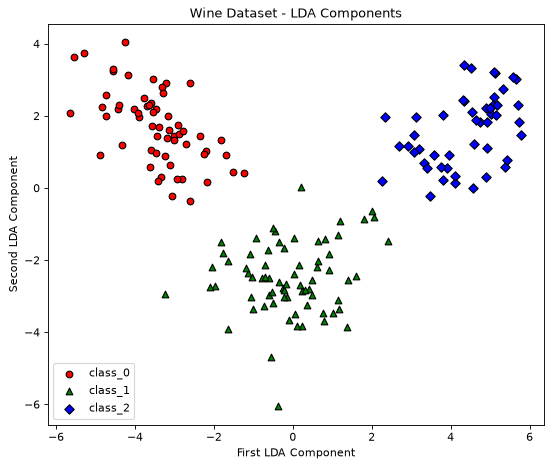

Explained variance ratio (rasio diskriminan) LDA: [0.6875 0.3125]
Akurasi training LDA sebagai classifier       : 1.0


In [7]:
# Pisahkan fitur dan target
X_wine, y_wine = wine.data, wine.target

# Pipeline LDA: n_components <= min(n_features, n_classes - 1) = 2 untuk Wine
lda_pipeline_wine = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(n_components=2))
])

# Fit dan transform (LDA butuh label y!)
X_lda_wine = lda_pipeline_wine.fit_transform(X_wine, y_wine)

# Visualisasi hasil LDA
plt.figure(figsize=(8, 6.5))
shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']

for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_lda_wine[mask, 0], X_lda_wine[mask, 1],
                c=color, marker=shape, edgecolor='black',
                label=wine.target_names[i])

plt.xlabel('First LDA Component')
plt.ylabel('Second LDA Component')
plt.title('Wine Dataset - LDA Components')
plt.legend()
plt.show()

lda = lda_pipeline_wine.named_steps['lda']
print('Explained variance ratio (rasio diskriminan) LDA:', np.round(lda.explained_variance_ratio_, 4))
print('Akurasi training LDA sebagai classifier       :', round(lda_pipeline_wine.score(X_wine, y_wine), 4))

**Interpretasi:** Pada ruang LDA, ketiga kelas membentuk tiga gugus yang **rapat dan terpisah sempurna** tanpa tumpang tindih. Komponen LD1 menampung ≈ **68,7%** daya diskriminatif dan memisahkan `class_0` (kiri), `class_1` (tengah), `class_2` (kanan); LD2 (≈ 31,3%) terutama mengangkat `class_1` menjauh dari dua kelas lain. Karena pipeline yang sama juga merupakan classifier, akurasi pada data latih mencapai 100% — angka ini optimistis karena diukur pada data yang sama dengan data *fit*, namun konsisten dengan keterpisahan visual yang sangat baik.

### 3.2.1 How it works — Perbandingan PCA vs LDA

**Teori:** PCA dan LDA sama-sama mencari proyeksi linear $Z = XW$, tetapi dengan fungsi objektif berbeda:

| Aspek | PCA | LDA |
|---|---|---|
| Label | Tidak dipakai | Dipakai |
| Objektif | $\max_{\mathbf{w}} \mathbf{w}^\top\Sigma\mathbf{w}$ (variansi total) | $\max_{\mathbf{w}} \dfrac{\mathbf{w}^\top S_B\mathbf{w}}{\mathbf{w}^\top S_W\mathbf{w}}$ (keterpisahan kelas) |
| Masalah eigen | $\Sigma\mathbf{w}=\lambda\mathbf{w}$ | $S_B\mathbf{w}=\lambda S_W\mathbf{w}$ |
| Ortogonalitas arah | Arah ortogonal | Arah umumnya **tidak** ortogonal di ruang asli ($S_W$-ortogonal) |
| Jumlah komponen maks. | $\min(n-1, p)$ | $\min(p, C-1)$ |
| Risiko | Arah variansi besar belum tentu diskriminatif | Overfitting jika $p$ besar & $n$ kecil; asumsi Gaussian & kovarians sama |

Contoh klasik: dua kelas berbentuk elips memanjang yang sejajar. Arah variansi terbesar (PC1) sejajar dengan elips sehingga proyeksi ke PC1 mencampur kedua kelas, sedangkan LDA memilih arah tegak lurus yang memisahkannya. Kode berikut menampilkan hasil keduanya berdampingan pada Wine.

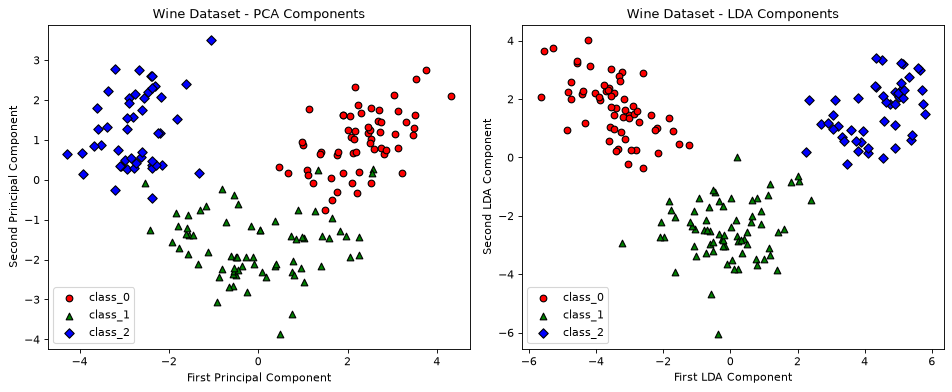

Rasio tr(S_B)/tr(S_W) di ruang PCA : 3.406
Rasio tr(S_B)/tr(S_W) di ruang LDA : 6.605


In [8]:
# Plot berdampingan: PCA (kiri) vs LDA (kanan)
plt.figure(figsize=(12, 5))

plt.subplot(121)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=color, marker=shape, edgecolor='black',
                label=wine.target_names[i])
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - PCA Components')
plt.legend()

plt.subplot(122)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(X_lda_wine[mask, 0], X_lda_wine[mask, 1],
                c=color, marker=shape, edgecolor='black',
                label=wine.target_names[i])
plt.xlabel('First LDA Component')
plt.ylabel('Second LDA Component')
plt.title('Wine Dataset - LDA Components')
plt.legend()

plt.tight_layout()
plt.show()

# Ukuran kuantitatif keterpisahan: rasio Fisher J = tr(S_B) / tr(S_W) di masing-masing ruang 2D
def fisher_ratio(Z, y):
    mu = Z.mean(axis=0)
    S_W = sum(((Z[y == c] - Z[y == c].mean(0)).T @ (Z[y == c] - Z[y == c].mean(0))) for c in np.unique(y))
    S_B = sum((y == c).sum() * np.outer(Z[y == c].mean(0) - mu, Z[y == c].mean(0) - mu) for c in np.unique(y))
    return np.trace(S_B) / np.trace(S_W)

print(f'Rasio tr(S_B)/tr(S_W) di ruang PCA : {fisher_ratio(X_pca, y_wine):.3f}')
print(f'Rasio tr(S_B)/tr(S_W) di ruang LDA : {fisher_ratio(X_lda_wine, y_wine):.3f}')

**Interpretasi:** Secara visual kedua proyeksi mirip — keduanya menyusun kelas dalam urutan `class_0` – `class_1` – `class_2` — karena pada dataset Wine arah variansi terbesar kebetulan juga cukup diskriminatif. Perbedaannya terletak pada kerapatan gugus: di ruang PCA, `class_1` masih menyebar dan bersinggungan dengan dua kelas lainnya, sedangkan di ruang LDA tiap kelas jauh lebih padat dan terpisah. Rasio sebaran antar-kelas terhadap dalam-kelas (kode tambahan kami) sekitar 3,4 di ruang PCA dan 6,6 di ruang LDA — hampir dua kali lipat — mengonfirmasi hal ini secara kuantitatif — wajar, karena kriteria itulah yang dioptimalkan LDA.

### Best Practices & Common Pitfalls LDA

**Praktik baik:**
1. Lakukan *scaling* fitur (tidak memengaruhi arah diskriminan secara teoretis untuk solver `svd`, tetapi membantu stabilitas numerik dan interpretasi koefisien).
2. Gunakan LDA ketika tujuan utamanya adalah keterpisahan kelas (pra-pemrosesan untuk klasifikasi, visualisasi data berlabel).
3. Periksa asumsi: distribusi fitur per kelas mendekati normal dan matriks kovarians antarkelas mirip (homoskedastisitas).
4. Untuk $p$ besar dan $n$ kecil gunakan *shrinkage* (`solver='lsqr'` atau `'eigen'` dengan `shrinkage='auto'`).

**Kesalahan umum:**
- Menerapkan LDA pada kelas yang sangat tidak seimbang tanpa memperhatikan *prior* $\pi_c$.
- Menerapkan pada data yang sangat tidak normal atau multimodal per kelas.
- Memakai LDA ketika kovarians antar kelas sangat berbeda (QDA lebih cocok).
- Meminta `n_components` lebih besar dari $C-1$ (scikit-learn akan menolak).
- Mengevaluasi performa pada data latih yang sama (hasil terlalu optimistis) — gunakan *cross-validation*.

## 3.3 t-SNE untuk Visualisasi Data

**Teori:**

*t-distributed Stochastic Neighbor Embedding* (t-SNE; van der Maaten & Hinton, 2008) adalah teknik **non-linear** (*manifold learning*) yang dirancang khusus untuk **visualisasi** data berdimensi tinggi ke 2D/3D. Alih-alih mempertahankan variansi atau jarak global, t-SNE berusaha mempertahankan **ketetanggaan lokal**: titik-titik yang dekat di ruang asli harus tetap dekat di peta.

**1. Kemiripan di ruang asli (Gaussian).** Untuk setiap titik $\mathbf{x}_i$, probabilitas bersyarat bahwa $\mathbf{x}_i$ memilih $\mathbf{x}_j$ sebagai tetangga:

$$
p_{j\mid i} = \frac{\exp\!\left(-\|\mathbf{x}_i-\mathbf{x}_j\|^2 / 2\sigma_i^2\right)}{\sum_{k\ne i}\exp\!\left(-\|\mathbf{x}_i-\mathbf{x}_k\|^2 / 2\sigma_i^2\right)},
\qquad
p_{ij} = \frac{p_{j\mid i}+p_{i\mid j}}{2n}.
$$

Lebar kernel $\sigma_i$ dipilih per titik (lewat *binary search*) sehingga distribusi $P_i$ memiliki **perplexity** yang ditentukan pengguna:

$$
\operatorname{Perp}(P_i) = 2^{H(P_i)},\qquad H(P_i) = -\sum_j p_{j\mid i}\log_2 p_{j\mid i}.
$$

Perplexity dapat dibaca sebagai "jumlah tetangga efektif" (default scikit-learn = 30; nilai umum 5–50). Daerah padat mendapat $\sigma_i$ kecil, daerah jarang mendapat $\sigma_i$ besar.

**2. Kemiripan di ruang peta (Student-t).** Untuk titik peta $\mathbf{y}_i\in\mathbb{R}^2$ digunakan distribusi Student-t dengan 1 derajat kebebasan (Cauchy):

$$
q_{ij} = \frac{\left(1+\|\mathbf{y}_i-\mathbf{y}_j\|^2\right)^{-1}}{\sum_{k\ne l}\left(1+\|\mathbf{y}_k-\mathbf{y}_l\|^2\right)^{-1}} .
$$

Ekor distribusi-t yang berat mengatasi **crowding problem**: di 2D tidak ada cukup "ruang" untuk menempatkan semua tetangga berjarak sedang dari dimensi tinggi, sehingga titik yang cukup jauh diizinkan menjadi sangat jauh di peta. Hasilnya gugus-gugus tampak terpisah dengan jelas.

**3. Fungsi biaya: KL divergence.** Posisi $\mathbf{y}_i$ dioptimalkan dengan *gradient descent* untuk meminimalkan

$$
C = \mathrm{KL}(P\,\|\,Q) = \sum_{i\ne j} p_{ij}\log\frac{p_{ij}}{q_{ij}},
\qquad
\frac{\partial C}{\partial \mathbf{y}_i} = 4\sum_{j}(p_{ij}-q_{ij})(\mathbf{y}_i-\mathbf{y}_j)\left(1+\|\mathbf{y}_i-\mathbf{y}_j\|^2\right)^{-1}.
$$

KL divergence tidak simetris: biaya besar jika $p_{ij}$ besar tapi $q_{ij}$ kecil (tetangga dekat dipisahkan), dan biaya kecil sebaliknya. Itulah mengapa t-SNE sangat menjaga struktur lokal tetapi **tidak menjamin struktur global** (jarak antar-gugus dan ukuran gugus di peta tidak bermakna kuantitatif).

**4. Detail implementasi scikit-learn.** `TSNE` memakai pendekatan Barnes–Hut ($\mathcal{O}(n\log n)$) secara default, *early exaggeration* (memperbesar $p_{ij}$ pada iterasi awal agar gugus terbentuk), `learning_rate='auto'` dan `init='pca'` (default sejak versi 1.2). Jumlah iterasi kini diatur dengan `max_iter` (parameter lama `n_iter` sudah dihapus). t-SNE **tidak memiliki metode `transform`** untuk data baru — hanya `fit_transform` — sehingga tidak cocok sebagai langkah pra-pemrosesan dalam pipeline prediktif.

**Getting ready.** Kita memakai dataset **Digits** (versi UCI *Optical Recognition of Handwritten Digits*): 1.797 citra angka tulisan tangan 0–9 berukuran 8×8 piksel. Setiap citra diperoleh dari bitmap 32×32 yang dibagi menjadi blok 4×4 lalu dihitung jumlah piksel aktif per blok, sehingga tiap piksel bernilai bilangan bulat 0–16. Hasilnya adalah 64 fitur per sampel.

Shape data: (1797, 64) | jumlah kelas: 10
Rentang nilai piksel: 0.0 - 16.0


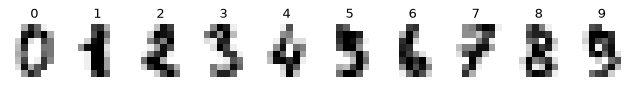

In [9]:
# Load dataset Digits
digits = load_digits()
print('Shape data:', digits.data.shape, '| jumlah kelas:', len(digits.target_names))
print('Rentang nilai piksel:', digits.data.min(), '-', digits.data.max())

# Tampilkan beberapa contoh citra
fig, axes = plt.subplots(1, 10, figsize=(10, 1.6))
for ax, img, lab in zip(axes, digits.images, digits.target):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(lab)
    ax.axis('off')
plt.show()

**Interpretasi:** Dataset berisi 1.797 sampel × 64 fitur (piksel 8×8) dengan nilai 0–16 untuk 10 kelas digit. Contoh citra di atas memperlihatkan resolusinya yang rendah, tetapi bentuk angka masih dapat dikenali. Ruang 64 dimensi ini mustahil divisualisasikan langsung, sehingga cocok untuk didemonstrasikan dengan t-SNE.

### 3.3.1 How to do it — t-SNE dalam `Pipeline`

Sama seperti sebelumnya, data distandardisasi lebih dulu lalu dipetakan ke 2D dengan `TSNE(n_components=2, random_state=2024)`. `random_state` penting karena t-SNE adalah optimasi non-konveks: inisialisasi berbeda bisa menghasilkan peta berbeda. Pipeline yang berakhir dengan t-SNE hanya bisa memanggil `fit_transform` (bukan `transform`).

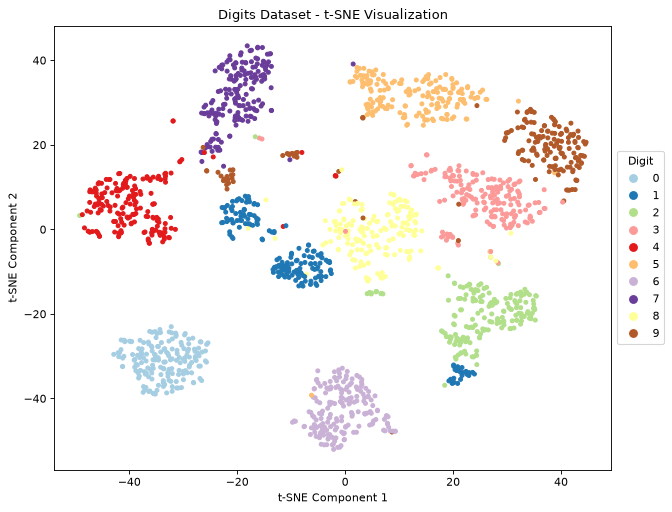

KL divergence akhir : 0.8369
Iterasi dijalankan  : 999


In [10]:
# Pipeline: standardisasi -> t-SNE 2D
tsne_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('tsne', TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=2024))
])

# Fit dan transform (t-SNE tidak punya .transform() terpisah)
X_tsne = tsne_pipeline.fit_transform(digits.data)

# Visualisasi hasil t-SNE
plt.figure(figsize=(8.5, 6.5))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap='Paired', s=12)
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('Digits Dataset - t-SNE Visualization')

# Legend manual per digit
legend_elements = [plt.Line2D([0], [0], marker='o', color='w',
                              markerfacecolor=plt.cm.Paired(i / 9),
                              label=str(i), markersize=9)
                   for i in range(10)]
plt.legend(handles=legend_elements, title='Digit', loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

tsne = tsne_pipeline.named_steps['tsne']
print(f'KL divergence akhir : {tsne.kl_divergence_:.4f}')
print(f'Iterasi dijalankan  : {tsne.n_iter_}')

**Interpretasi:** Peta t-SNE memperlihatkan sepuluh gugus yang sebagian besar terpisah jelas, masing-masing didominasi satu digit — padahal t-SNE tidak memakai label (warna hanya ditambahkan untuk evaluasi visual). Digit dengan bentuk khas seperti 0, 6, 4, dan 5 membentuk gugus yang rapat dan terisolasi. Digit 1 terpecah menjadi beberapa sub-gugus (salah satunya menempel pada gugus digit 2), mencerminkan variasi gaya penulisan angka satu; sekelompok kecil digit 9 juga terpisah dari gugus utamanya dan berada dekat digit 7, dan beberapa titik digit 8 berdekatan dengan 1 dan 3. KL divergence akhir ≈ 0,84 menunjukkan distribusi $Q$ di peta cukup mendekati $P$ di ruang asli. Ingat: jarak antargugus dan ukuran gugus di peta **tidak** dapat ditafsirkan secara kuantitatif.

### Best Practices & Common Pitfalls t-SNE

**Praktik baik:**
1. Lakukan *scaling* sebelum t-SNE; untuk data berdimensi sangat tinggi, reduksi dulu dengan PCA (mis. ke 50 dimensi) untuk mengurangi noise dan mempercepat komputasi.
2. Bereksperimen dengan `perplexity` (5–50) dan bandingkan beberapa `random_state`; struktur yang stabil di banyak setelan lebih bisa dipercaya.
3. Gunakan t-SNE terutama untuk eksplorasi dan visualisasi.

**Kesalahan umum:**
- Memakai t-SNE sebagai langkah reduksi dimensi di pipeline prediktif — tidak ada `transform` untuk data baru dan hasilnya tidak deterministik antar *run*.
- Menafsirkan berlebihan struktur global: jarak antargugus, ukuran gugus, dan kepadatan relatif tidak bermakna.
- Tidak menyetel perplexity: terlalu kecil memunculkan gugus palsu, terlalu besar meleburkan gugus.
- Menjalankan iterasi terlalu sedikit sehingga optimasi belum konvergen.

## 3.4 Latihan (Practical Exercises)

Bagian ini mereproduksi solusi latihan dari notebook *Exercise Solution* penerbit.

### Latihan 1: PCA + Logistic Regression

**Teori:** PCA sering dipakai sebagai langkah pra-pemrosesan sebelum *classifier*. Dengan `PCA(n_components=0.95)`, scikit-learn memilih $k$ terkecil sehingga $\sum_{j\le k}\lambda_j/\sum_i\lambda_i \ge 0{,}95$. Manfaat potensialnya: jumlah parameter model berkurang (Logistic Regression multikelas memiliki $C\times(k+1)$ parameter), training lebih cepat, multikolinearitas hilang (fitur PC tidak berkorelasi), dan kadang efek regularisasi karena dimensi ber-variansi kecil (sering berisi noise) dibuang. Risikonya: arah dengan variansi kecil bisa saja penting untuk membedakan kelas, sehingga akurasi bisa sedikit turun.

Logistic Regression multinomial memodelkan

$$
P(y=c\mid\mathbf{z}) = \frac{\exp(\boldsymbol\beta_c^\top\mathbf{z} + b_c)}{\sum_{c'}\exp(\boldsymbol\beta_{c'}^\top\mathbf{z} + b_{c'})},
$$

dengan $\mathbf{z}$ = fitur asli terstandardisasi (tanpa PCA) atau skor PC (dengan PCA). Kita membandingkan akurasi kedua pipeline pada data uji Digits (80/20 split).

In [11]:
# Load library
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.2, random_state=2024
)

# Pipeline tanpa PCA
pipeline_no_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])

# Pipeline dengan PCA (pertahankan 95% variansi)
pipeline_with_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95)),
    ('clf', LogisticRegression(max_iter=1000))
])

# Fit kedua pipeline
pipeline_no_pca.fit(X_train, y_train)
pipeline_with_pca.fit(X_train, y_train)

# Hasil
print('Accuracy without PCA:', round(accuracy_score(y_test, pipeline_no_pca.predict(X_test)), 4))
print('Accuracy with PCA   :', round(accuracy_score(y_test, pipeline_with_pca.predict(X_test)), 4))
print('Jumlah fitur awal                  :', X_train.shape[1])
print('Jumlah komponen PCA (95% variansi) :', pipeline_with_pca.named_steps['pca'].n_components_)

Accuracy without PCA: 0.975
Accuracy with PCA   : 0.9639
Jumlah fitur awal                  : 64
Jumlah komponen PCA (95% variansi) : 39


**Interpretasi:** Tanpa PCA, Logistic Regression mencapai akurasi uji ≈ **97,5%**; dengan PCA (95% variansi) akurasinya ≈ **96,4%**. PCA memangkas dimensi dari 64 menjadi **39** komponen (≈ 39% lebih sedikit) dengan penurunan akurasi hanya sekitar 1 poin persentase. Ini menggambarkan *trade-off* khas PCA: efisiensi dan kesederhanaan model diperoleh dengan sedikit kehilangan informasi diskriminatif (yang tersimpan di 5% variansi yang dibuang). Pada dataset kecil seperti Digits manfaat kecepatan tidak terasa, tetapi pada data berdimensi ribuan efeknya signifikan.

### Latihan 2: t-SNE untuk Visualisasi Hasil Clustering

**Teori:** t-SNE juga berguna untuk **memvisualisasikan hasil clustering**. Di sini K-Means dengan $K=10$ dijalankan pada data Digits asli (64 dimensi), lalu label cluster-nya diwarnai di atas peta t-SNE yang sama dengan sebelumnya. K-Means meminimalkan *within-cluster sum of squares* (inersia):

$$
\min_{\{C_k\},\{\boldsymbol\mu_k\}} \sum_{k=1}^{K}\sum_{\mathbf{x}_i\in C_k}\|\mathbf{x}_i-\boldsymbol\mu_k\|^2,
$$

dengan algoritme Lloyd (alternasi *assignment* ke centroid terdekat dan *update* centroid). Karena label cluster bersifat arbitrer (cluster 3 belum tentu digit 3), kesesuaian dengan label asli diukur dengan **Adjusted Rand Index** (tambahan kami), yang invarian terhadap permutasi label:

$$
\mathrm{ARI} = \frac{\mathrm{RI} - \mathbb{E}[\mathrm{RI}]}{\max(\mathrm{RI}) - \mathbb{E}[\mathrm{RI}]},
$$

bernilai 1 untuk kecocokan sempurna dan ≈ 0 untuk penugasan acak.

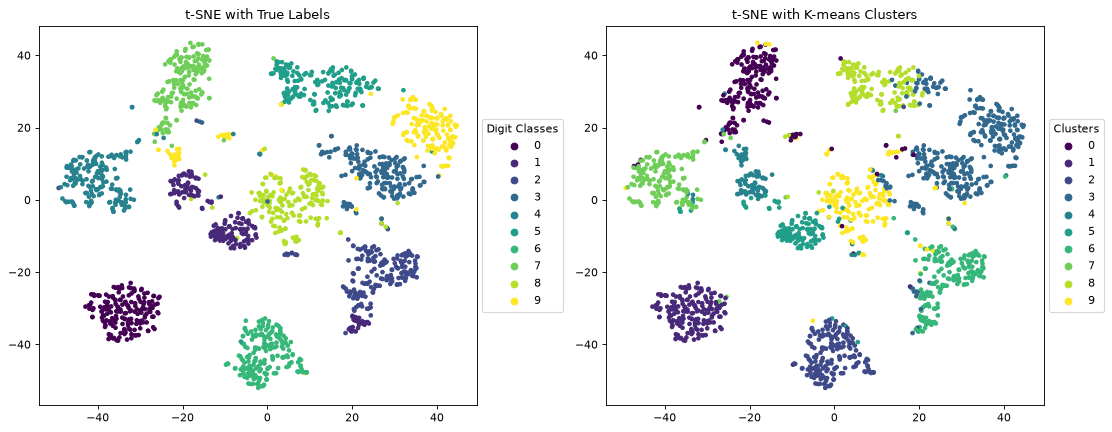

Adjusted Rand Index (K-Means vs label asli): 0.657


Cluster,0,1,2,3,4,5,6,7,8,9
Digit,,,,,,,,,,
0,0,176,0,0,0,0,0,2,0,0
1,0,0,2,0,53,101,25,0,1,0
2,2,1,0,11,2,2,148,0,0,11
3,8,0,0,161,0,0,2,0,2,10
4,7,0,0,0,3,5,0,163,0,3
5,0,0,2,40,0,0,0,2,138,0
6,0,1,176,0,0,3,0,0,0,1
7,174,0,0,0,2,0,0,0,0,3
8,3,0,1,12,7,10,3,0,2,136


In [12]:
# Load library
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# K-Means clustering pada data asli (64 dimensi)
kmeans = KMeans(n_clusters=10, n_init='auto', random_state=2024)
cluster_labels = kmeans.fit_predict(digits.data)

# Plot berdampingan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Kiri: warna = label asli
scatter1 = ax1.scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap='viridis', s=10)
ax1.set_title('t-SNE with True Labels')
ax1.legend(*scatter1.legend_elements(), title='Digit Classes',
           loc='center left', bbox_to_anchor=(1, 0.5))

# Kanan: warna = label cluster K-Means
scatter2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=cluster_labels, cmap='viridis', s=10)
ax2.set_title('t-SNE with K-means Clusters')
ax2.legend(*scatter2.legend_elements(), title='Clusters',
           loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

print(f'Adjusted Rand Index (K-Means vs label asli): {adjusted_rand_score(digits.target, cluster_labels):.3f}')
# Tabel kontingensi: digit asli (baris) vs cluster (kolom)
display(pd.crosstab(pd.Series(digits.target, name='Digit'), pd.Series(cluster_labels, name='Cluster')))

**Interpretasi:** Pewarnaan cluster K-Means pada peta t-SNE sebagian besar mengikuti gugus digit asli: banyak gugus t-SNE berwarna seragam di plot kanan, artinya K-Means (yang bekerja di ruang 64D, bukan di peta 2D) menemukan pengelompokan yang selaras dengan struktur lokal yang dipertahankan t-SNE. Namun kecocokannya tidak sempurna — ARI ≈ **0,66**. Tabel kontingensi menunjukkan digit 0, 6, 7, 4, dan 3 hampir seluruhnya jatuh ke satu cluster masing-masing, sedangkan digit 1 terpecah ke tiga cluster (sebagian bergabung dengan digit 2), mayoritas digit 9 justru bergabung dengan digit 3 dalam satu cluster, dan sekitar 40 sampel digit 5 ikut masuk ke cluster tersebut. Penyebabnya: K-Means mengasumsikan cluster berbentuk bola dengan ukuran mirip dan memakai jarak Euclidean pada piksel mentah, sedangkan variasi gaya tulisan tangan tidak selalu sesuai asumsi itu. Visualisasi t-SNE sangat membantu untuk mendiagnosis di mana clustering gagal.

## Ringkasan Chapter 3

**Inti materi:**
- **Reduksi dimensi** memetakan data dari $\mathbb{R}^p$ ke $\mathbb{R}^k$ ($k\ll p$) untuk melawan *curse of dimensionality*, mempercepat komputasi, mengurangi *overfitting*/multikolinearitas, dan memungkinkan visualisasi.
- **PCA** (unsupervised, linear) mencari arah ortogonal dengan variansi maksimum, yaitu eigenvector matriks kovarians $\Sigma\mathbf{w}=\lambda\mathbf{w}$ (dihitung praktis lewat SVD $X=USV^\top$). *Explained variance ratio* $\lambda_j/\sum\lambda_i$ memandu pemilihan jumlah komponen. Pada Wine, 2 PC menjelaskan ≈ 55% variansi namun sudah memisahkan tiga kultivar; 10 PC diperlukan untuk ≥ 95%.
- Dengan $k=p$, PCA hanyalah **rotasi** sumbu yang membuat fitur tidak berkorelasi; manfaat reduksi bergantung pada kuatnya korelasi antarfitur (contoh 2 fitur: EVR PC1 $=(1+|r|)/2$).
- **LDA** (supervised, linear) memaksimalkan kriteria Fisher $\mathbf{w}^\top S_B\mathbf{w}/\mathbf{w}^\top S_W\mathbf{w}$ melalui masalah eigen tergeneralisasi, menghasilkan maksimal $C-1$ komponen, dan sekaligus dapat berfungsi sebagai classifier. Pada Wine, LDA menghasilkan gugus kelas yang jauh lebih rapat dan terpisah dibanding PCA.
- **t-SNE** (unsupervised, non-linear) mencocokkan kemiripan Gaussian di ruang asli dengan kemiripan Student-t di peta 2D dengan meminimalkan $\mathrm{KL}(P\|Q)$; parameter kunci adalah `perplexity`. Pada Digits, t-SNE memisahkan 10 digit dengan sangat jelas tanpa label.
- **Latihan:** PCA 95% memangkas fitur Digits dari 64 ke 39 dengan akurasi Logistic Regression turun hanya ≈ 1 poin (97,5% → 96,4%); t-SNE memperlihatkan bahwa K-Means (ARI ≈ 0,66) menangkap sebagian besar, tetapi tidak semua, struktur digit.

**Key takeaways:**
1. **Selalu standardisasi** fitur sebelum PCA/LDA/t-SNE, dan bungkus langkah-langkahnya dalam `Pipeline`.
2. **Pilih teknik sesuai tujuan:** PCA untuk kompresi/pra-pemrosesan umum tanpa label, LDA bila label tersedia dan keterpisahan kelas yang diinginkan, t-SNE khusus untuk visualisasi eksploratif.
3. **Variansi tinggi ≠ informatif untuk klasifikasi** — itulah perbedaan mendasar PCA dan LDA.
4. **Jangan memakai t-SNE di pipeline prediktif** dan jangan menafsirkan jarak global/ukuran gugus di peta t-SNE.
5. Reduksi dimensi selalu merupakan **trade-off** antara kesederhanaan/efisiensi dan informasi yang hilang; ukur dampaknya (explained variance, akurasi validasi) alih-alih mengasumsikannya.
6. Penyesuaian API untuk scikit-learn modern: t-SNE memakai `max_iter` (bukan `n_iter`), default `init='pca'` dan `learning_rate='auto'`; K-Means memakai `n_init='auto'`.